##  Robust Bias Correction for Bioage Prediction
## Comparing Linear, RANSAC and Theil-Sen Calibration on Synthetic Data

### Цель:
Сравнить три метода линейной калибровки биовозраста:
 - `LinearRegression` — чувствителен к выбросам  
 - `RANSACRegressor` — устойчив, отбрасывает аномалии  
 - `TheilSenRegressor` — основана на медиане, очень робастна  

 Мы имитируем данные биовозраста с систематической ошибкой и выбросами.

## Генерация синтетических данных (аналог биовозраста)

 Представим:
 - `true_age` — реальный возраст (20–85 лет)  
 - `bioage_raw` — предсказанный биовозраст с систематической ошибкой и шумом  
 - Добавим выбросы для имитации "плохих" пациентов

In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, RANSACRegressor, TheilSenRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

np.random.seed(42)
n_samples = 500

# Истинный возраст: нормальное распределение вокруг 45 лет
true_age = np.random.normal(45, 25, n_samples)
true_age = np.clip(true_age, 20, 85)  # Ограничим диапазон

# Биовозраст — линейная связь + шум + систематическая ошибка
bioage_raw = (
    0.9 * true_age +                    # слабая корреляция (как в реальности)
    np.random.normal(0, 2, n_samples)   # случайный шум
)

# Добавим систематическую ошибку: у пожилых — недооценка, у молодых — переоценка
bioage_raw += np.where(true_age > 70,  np.random.uniform(-6, 0), 0)      # пожилые кажутся моложе
bioage_raw += np.where(true_age < 30,  np.random.uniform(0, 5), 0)      # молодые кажутся старше

# Добавим **5% выбросов** — люди с очень большими ошибками (например, аномальные биомаркеры)
n_outliers = int(0.05 * n_samples)
outlier_indices = np.random.choice(n_samples, size=n_outliers, replace=False)

# Выбросы: у них биовозраст сильно отклоняется
bioage_raw[outlier_indices] += np.random.choice([-12, 12], size=n_outliers) * np.random.uniform(0.8, 1.5, n_outliers)

# Разделим данные на train/test
idx = np.arange(n_samples)
np.random.shuffle(idx)
train_size = int(0.7 * n_samples)


X = pd.DataFrame({
    'feature_1': bioage_raw*0.1+np.random.normal(0, 1, n_samples),
    'feature_2': -bioage_raw*0.03+np.random.normal(0, 1, n_samples),
    'feature_3': bioage_raw*0.001-np.random.uniform(-1, 1, n_samples)
})

# Разбиваем индексы на train/test
idx = np.arange(n_samples)
np.random.shuffle(idx)

train_size = int(0.7 * n_samples)

X_train = X.iloc[idx[:train_size]]
y_train = true_age[idx[:train_size]]

X_test = X.iloc[idx[train_size:]]
y_test = true_age[idx[train_size:]]

# Предсказания модели (не трогаем)
bioage_train_raw = bioage_raw[idx[:train_size]]
bioage_test_raw = bioage_raw[idx[train_size:]]


print(f"Train size: {len(y_train)}, Test size: {len(y_test)}")
print(f"True age range: [{true_age.min():.1f}, {true_age.max():.1f}]")
print(f"Bioage raw mean error: {np.mean(bioage_raw - true_age):.2f} ± {np.std(bioage_raw - true_age):.2f}")



Train size: 350, Test size: 150
True age range: [20.0, 85.0]
Bioage raw mean error: -4.91 ± 5.26


## Базовая модель (предсказывает bioage, как есть)

KNN предсказывает биовозраст без коррекции.

In [10]:
from sklearn.neighbors import KNeighborsRegressor

# Обучаем KNN на обучающих данных
knn_model = KNeighborsRegressor(n_neighbors=22, weights='distance')  # n_neighbors — гиперпараметр
knn_model.fit(X_train, y_train)

# Предсказания KNN (это будет наш "сырой" биовозраст)
bioage_train_pred_knn = knn_model.predict(X_train)
bioage_test_pred_knn = knn_model.predict(X_test)

print(" KNN Model Performance:")
print(f"  Train R²: {r2_score(y_train, bioage_train_pred_knn):.4f}, MAE: {mean_absolute_error(y_train, bioage_train_pred_knn):.3f}")
print(f"  Test R²:  {r2_score(y_test, bioage_test_pred_knn):.4f}, MAE: {mean_absolute_error(y_test, bioage_test_pred_knn):.3f}")

# Теперь создадим модель, которая просто возвращает предсказания KNN
class KNNBioAgeModel:
    def __init__(self, knn_model):
        self.knn_model = knn_model
    
    def predict(self, X):
        return self.knn_model.predict(X)

my_bioage_model = KNNBioAgeModel(knn_model) 

 KNN Model Performance:
  Train R²: 1.0000, MAE: 0.000
  Test R²:  0.7000, MAE: 8.786


##  Реализация LinearBiasCorrector с поддержкой RANSAC, Theil-Sen 

In [46]:
import numpy as np
from sklearn.linear_model import LinearRegression, TheilSenRegressor, RANSACRegressor
#from ._version import __version_tuple__, __version__
import yaml



class LinearBiasCorrector:
    def __init__(self, regressor_type='linear', regressor_params=None):
        self.regressor_type = regressor_type  # 'linear', 'theilsen', 'ransac'
        self.regressor_params = regressor_params or {}  # dict with params for non-linear models
        self.rotation_lr = None
        self.intercept_lr = None

    def _get_coefficients(self, model):
        if self.regressor_type == 'linear':
            return model.coef_[0], model.intercept_
        elif self.regressor_type == 'theilsen':
            # TheilSenRegressor имеет coef_ и intercept_ напрямую!
            return model.coef_[0], model.intercept_
        elif self.regressor_type == 'ransac':
            # RANSACRegressor — обёртка, коэффициенты в estimator_
            return model.estimator_.coef_[0], model.estimator_.intercept_
        else:
            raise ValueError(f"Unknown regressor_type: {self.regressor_type}")
            
    def fit(self, true_train, pred_train):
        true_train = np.array(true_train).reshape(-1, 1)
        pred_train = np.array(pred_train)

        if self.regressor_type == 'linear':
            ln = LinearRegression()
        elif self.regressor_type == 'theilsen':
            ln = TheilSenRegressor(random_state=42, **self.regressor_params)
        elif self.regressor_type == 'ransac':
            params = dict(random_state=42, **self.regressor_params)
            ln = RANSACRegressor(**params)
        else:
            raise ValueError(f"Unknown regressor_type: {self.regressor_type}")

        ln.fit(true_train, pred_train)
        #slope, intercept = ln.coef_[0], ln.intercept_
        slope, intercept = self._get_coefficients(ln)
        self.rotation_lr, self.intercept_lr = self.transform_line_linreg(slope, 1, intercept)

    def predict(self, pred_train):
        if self.rotation_lr is None or self.intercept_lr is None:
            raise ValueError("Model must be fitted before predicting.")
        return np.array(pred_train) * self.rotation_lr + self.intercept_lr

    def transform_line_linreg(self, slope1, slope2, intercept):
        rotation_factor = slope2 / slope1
        d = -intercept / slope1
        return rotation_factor, d

    @classmethod
    def load(cls, path_to_yml):
        with open(path_to_yml, 'r') as fin:
            model_dict = yaml.full_load(fin)
        corrector = LinearBiasCorrector(
            regressor_type=model_dict.get('regressor_type', 'linear'),
            regressor_params=model_dict.get('regressor_params', {})
        )
        corrector.rotation_lr = model_dict['rotation_lr']
        corrector.intercept_lr = model_dict['intercept_lr']
        return corrector

    def save(self, path_to_yml):
        model_dict = {
            'model_name': 'linear_bias_correction',
            #'version': __version__,
            #'version_tuple': __version_tuple__,
            'regressor_type': self.regressor_type,
            'regressor_params': self.regressor_params,  # <-- сохраняем параметры
            'rotation_lr': self.rotation_lr.item(),
            'intercept_lr': self.intercept_lr.item()
        }
        with open(path_to_yml, 'w') as fout:
            yaml.dump(model_dict, fout, default_flow_style=False)

    def __str__(self):
        return f'Linear bias corrector (type={self.regressor_type}): a={self.rotation_lr} b={self.intercept_lr}'


In [4]:
LinearBiasCorrector

__main__.LinearBiasCorrector

##  Реализация AccModel с поддержкой RANSAC, Theil-Sen 


In [41]:
from abc import ABCMeta, abstractmethod
from regression_bias_corrector.linear_corrector import LinearBiasCorrector
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

class AnyModel(metaclass=ABCMeta):
    @abstractmethod
    def predict(self, X):
        pass

class AccModel:
    def __init__(
        self, bioage_model: AnyModel,
        need_fit=False, bias_correction=False, 
        bias_correction_regressor='linear', 
        bias_correction_regressor_params=None
    ):
        self.model = bioage_model
        self.linreg_model = None
        self.bias_correction = bias_correction
        self.need_fit = need_fit
        self.bias_correction_regressor = bias_correction_regressor
        self.bias_correction_regressor_params = bias_correction_regressor_params or {}

        if self.bias_correction:
            self.corrector = LinearBiasCorrector(
                regressor_type=bias_correction_regressor,
                regressor_params=bias_correction_regressor_params  # <-- передаём параметры
            )

    def _prepare_data(self, X: pd.DataFrame, ages: pd.Series):
        if type(X) is pd.DataFrame and type(ages) is pd.Series:
            ages = ages[X.index]
        return X, ages

    def fit(self, X: pd.DataFrame, ages: pd.Series):
        X, ages = self._prepare_data(X, ages)
        if self.need_fit:
            self.model.fit(X, ages)
        bioages = self.model.predict(X)
        if self.bias_correction:
            self.corrector.fit(ages, bioages)
            bioages = self.corrector.predict(bioages)
        ages = np.asarray(ages)  #  Универсальное приведение к NumPy array
        self.linreg_model = LinearRegression().fit(ages.reshape(-1, 1), bioages)    
        #self.linreg_model = LinearRegression().fit(ages.values.reshape(-1, 1), bioages)
        return self

    def predict(self, X: pd.DataFrame):
        bioages = self.model.predict(X)
        if self.bias_correction:
            bioages = self.corrector.predict(bioages)
        return bioages

    def predictacc(self, X: pd.DataFrame, ages: pd.Series):
        X, ages = self._prepare_data(X, ages)
        bioages = self.predict(X)
        acc = bioages - self.linreg_model.predict(ages.values.reshape(-1, 1))
        return acc

    def __str__(self):
        return str(self.model) + ('\n' + str(self.corrector) if hasattr(self, 'corrector') else '')

    def plot_predict(self, X: pd.DataFrame, ages: pd.Series, seed=42):
        X, ages = self._prepare_data(X, ages)
        yp = self.predict(X)
        y1 = np.asarray(ages)  #  Универсальное приведение к NumPy array
        yl = self.linreg_model.predict(y1.reshape(-1, 1))
        #yl = self.linreg_model.predict(ages.values.reshape(-1, 1))

        import matplotlib.pyplot as plt
        plt.scatter(ages, yp)
        plt.plot(ages, yl, color='red')
        plt.plot(ages, ages, color='gray')
        colors = ['blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta',
                  'gold', 'indigo', 'maroon', 'navy', 'teal']
        np.random.seed(seed)
        for j in range(15):
            i = np.random.choice(len(ages))
            plt.arrow(np.array(ages)[i], yp[i], 0, -yp[i]+yl[i],
                      head_width=0.2, head_length=0.3, fc='k', ec='k')
            plt.scatter(np.array(ages)[i], yp[i], color=colors[j])
            plt.scatter(np.array(ages)[i], yl[i], color=colors[j])
        plt.xlabel('Age, years')
        plt.ylabel('Bioage, years')


In [81]:
_linreg_registry

{'linear': sklearn.linear_model._base.LinearRegression}

##  Функция plot_model_scatter

In [69]:
def _align_y_with_X(X, y):
    """
    Приводит y к 1‑D массиву и гарантирует,
    что порядок элементов совпадает с порядком строк X.
    """
    # 1) Приводим y к Series/ndarray, если это DataFrame – «выжимаем» колонку
    if isinstance(y, pd.Series):
        y_arr = y.values               # уже 1‑D
    elif isinstance(y, pd.DataFrame):
        y_arr = y.squeeze().values     # (n,1) → (n,)
    else:
        y_arr = np.asarray(y).ravel()

    # 2) Если X – DataFrame с индексом, то переиндексируем y по этому индексу
    if isinstance(X, pd.DataFrame):
        # .loc гарантирует, что порядок будет таким же, как у X
        y_aligned = pd.Series(y_arr, index=X.index).loc[X.index].values.ravel()
        return y_aligned
    else:
        # Если X – уже массив numpy, просто возвращаем y в виде 1‑D
        return y_arr.ravel()

def make_scatter_df(real_series, pred_series, set_name='test'):
    """
    Возвращает DataFrame с колонками:
        Real_jittered – реальное значение + небольшое случайное смещение (jitter)
        Predicted     – предсказанное моделью значение
        Set           – метка набора (нужна, если используете hue)
    """
    #  Добавляем «шум» к реальному значению.
    jitter = np.random.uniform(-0.5, 0.5, size=len(real_series))
    real_jittered = real_series + jitter

    #  Формируем DataFrame сразу со всеми нужными колонками
    df = pd.DataFrame({
        'Real_jittered': real_jittered,
        'Predicted'   : pred_series,
        'Set'         : set_name          # будет использовано в hue
    })
    return df

def plot_model_scatter(model, X_train, y_train, X_test, y_test, metrics = [0,0,0,0], title='', fn='', alpha=0.5, plot_train=True, plot_test=True):
    """
    Строит scatter-plot предсказаний модели для train и test наборов.
    Добавляет 2D KDE плотность распределения для визуализации концентрации точек.

    :param model: обученная модель с predict()
    :param X_train, y_train: обучающая выборка
    :param X_test, y_test: тестовая выборка
    :param title: заголовок графика
    :param fn: путь для сохранения PNG (опционально)
    :param alpha: прозрачность scatter-точек
 
    
    # Преобразуем y_train и y_test в 1D numpy array 
    if isinstance(y_train, pd.Series):
        y_train = y_train.values
    elif isinstance(y_train, pd.DataFrame):
        y_train = y_train.squeeze().values   # Убирает размерность (n,1) → (n,)
    else:
        y_train = np.array(y_train).ravel()

    if isinstance(y_test, pd.Series):
        y_test = y_test.values
    elif isinstance(y_test, pd.DataFrame):
        y_test = y_test.squeeze().values   # Убирает размерность (n,1) → (n,)
    else:
        y_test = np.array(y_test).ravel()

    
    # Предсказания — всегда ravel() для безопасности
    y_train_pred = model.predict(X_train).ravel()
    y_test_pred = model.predict(X_test).ravel()

    # Вычисление метрик
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    """
 
    #  Приводим y к нужному формату и выравниваем по индексам X
    
    y_train = _align_y_with_X(X_train, y_train)
    y_test  = _align_y_with_X(X_test , y_test )

    #  Предсказания – тоже ravel() (чтобы точно получить 1‑D)
    y_train_pred = model.predict(X_train).ravel()
    y_test_pred  = model.predict(X_test ).ravel()

    #  Метрики
    train_r2   = r2_score(y_train, y_train_pred)
    test_r2    = r2_score(y_test , y_test_pred)

    # скорректированный R²:
    n_train = len(y_train); p = 1          # один предиктор – y_pred
    r2adj_train = 1 - (1 - train_r2) * (n_train - 1) / (n_train - p - 1)

    n_test = len(y_test)
    r2adj_test = 1 - (1 - test_r2) * (n_test - 1) / (n_test - p - 1)

    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae  = mean_absolute_error(y_test , y_test_pred)

    #  Вывод/визуализация
    print(f'{title}')
    print(f'   Train  : R²={train_r2:.4f} , Adj‑R²={r2adj_train:.4f} , MAE={train_mae:.4f}')
    print(f'   Test   : R²={test_r2:.4f} , Adj‑R²={r2adj_test:.4f} , MAE={test_mae:.4f}')

    # Настройка стиля seaborn
    sns.set_style("whitegrid")
    fig, ax = plt.subplots(figsize=(7, 6))

    # Создаём DataFrame для удобства и красивой визуализации
    df_train = pd.DataFrame({'Real': y_train, 'Predicted': y_train_pred, 'Set': 'Train'})
    df_test = pd.DataFrame({'Real': y_test, 'Predicted': y_test_pred, 'Set': 'Test'})
    df_combined = pd.concat([df_train, df_test], ignore_index=True)

    # Строим scatter plot с seaborn
    df_comb = df_combined.copy()
    df_comb['Real_jittered'] = df_comb['Real'] + np.random.uniform(-0.5, 0.5, size=len(df_combined))
    #df_trainj = df_train['Real'] + np.random.uniform(-0.5, 0.5, size=len(df_train))
    #df_testj = df_test['Real'] + np.random.uniform(-0.5, 0.5, size=len(df_test))
    df_trainj = make_scatter_df(y_train, y_train_pred, set_name='train')
    df_testj  = make_scatter_df(y_test,  y_test_pred,  set_name='test')

    jitter_amount = 1e-6  # Очень маленький шум      # проверить в модуле!!!!
    # --- Построение 2D KDE для Train ---
    if plot_train:  # Нужно достаточно точек
        #kde_train = gaussian_kde([y_train, y_train_pred])

        y_train_jittered = y_train + np.random.normal(0, jitter_amount, size=len(y_train))
        y_train_pred_jittered = y_train_pred + np.random.normal(0, jitter_amount, size=len(y_train_pred))
        kde_train = gaussian_kde([y_train_jittered, y_train_pred_jittered])
        
        x_grid = np.linspace(min(y_train.min(), y_test.min()), max(y_train.max(), y_test.max()), 100)
        y_grid = np.linspace(min(y_train_pred.min(), y_test_pred.min()), max(y_train_pred.max(), y_test_pred.max()), 100)
        Xk, Yk = np.meshgrid(x_grid, y_grid)
        Zk = kde_train([Xk.ravel(), Yk.ravel()]).reshape(Xk.shape)

        contourf_train = ax.contourf(Xk, Yk, Zk, levels=8, cmap="Blues", alpha=0.4, zorder=1)
        # Добавляем контуры (для чёткости)
        contours_train = ax.contour(Xk, Yk, Zk, levels=8, colors=["#1f77b4"], linewidths=0.5, alpha=0.6, zorder=2)
        sns.scatterplot(
            data=df_trainj,
            x='Real_jittered',
            y='Predicted',
            hue='Set',
            alpha=0.5,
            s=10,
            palette=['blue']
        )       

    # --- Построение 2D KDE для Test ---
    if plot_test:
        #kde_test = gaussian_kde([y_test, y_test_pred])
        y_test_jittered = y_test + np.random.normal(0, jitter_amount, size=len(y_test))
        y_test_pred_jittered = y_test_pred + np.random.normal(0, jitter_amount, size=len(y_test_pred))
        kde_test = gaussian_kde([y_test_jittered, y_test_pred_jittered])
        
        x_grid = np.linspace(min(y_train.min(), y_test.min()), max(y_train.max(), y_test.max()), 100)
        y_grid = np.linspace(min(y_train_pred.min(), y_test_pred.min()), max(y_train_pred.max(), y_test_pred.max()), 100)
        Xk, Yk = np.meshgrid(x_grid, y_grid)
        Zk = kde_test([Xk.ravel(), Yk.ravel()]).reshape(Xk.shape)

        contourf_test = ax.contourf(Xk, Yk, Zk, levels=8, cmap="Reds", alpha=0.4, zorder=1)
        # Добавляем контуры
        contours_test = ax.contour(Xk, Yk, Zk, levels=8, colors=["#d62728"], linewidths=0.5, alpha=0.6, zorder=2)
    
        sns.scatterplot(
            data=df_testj,
            x='Real_jittered',
            y='Predicted',
            hue='Set',
            alpha=0.5,
            s=10,
            palette=['red']
        )

    # Идеальная линия: y = x
    min_val = min(y_train.min(), y_test.min(), y_train_pred.min(), y_test_pred.min())
    max_val = max(y_train.max(), y_test.max(), y_train_pred.max(), y_test_pred.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color='black',
        linestyle='--',
        linewidth=2,
        label='Perfect prediction (y=x)'
    )


    text_str = (
        f'Train R²: {metrics[2]} | MAE: {metrics[0]}\n'
        f'Test R²:  {metrics[3]} | MAE: {metrics[1]}'
    )
    ax.text(
        0.05, 0.95,
        text_str,
        transform=ax.transAxes,
        fontsize=11,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    )

    # Подписи
    ax.set_xlabel('Real Age', fontsize=12)
    ax.set_ylabel('Predicted Age', fontsize=12)
    ax.set_title(f'Age Prediction: {title}', fontsize=14, fontweight='bold')
    
    # Легенда — только для идеальной линии и KDE
    from matplotlib.patches import Patch
    legend_elements = [
        plt.Line2D([0], [0], color='black', linestyle='--', lw=2, label='Perfect prediction (y=x)'),
        Patch(color='blue', alpha=0.4, label='Train density (KDE)'),
        Patch(color='red', alpha=0.4, label='Test density (KDE)')
    ]
    ax.legend(handles=legend_elements, title='Legend', loc='lower right')

    # Улучшаем лейблы и выравнивание
    plt.tight_layout()
    fig.set_facecolor('white')
    
    if fn:
        fig.savefig(fn, transparent=False, facecolor='white', dpi=300)
        print(f" Scatter + KDE saved to: {fn}")

    plt.show()


## Сравнение трех методов на тестовой выборке


 Training AccModel with LINEAR...
   Test R²: 0.6241, MAE: 9.385

 Training AccModel with RANSAC...
   Test R²: 0.6612, MAE: 8.877

 Training AccModel with THEILSEN...
   Test R²: 0.6787, MAE: 8.801
AccModel (LINEAR)
   Train  : R²=0.6634 , Adj‑R²=0.6624 , MAE=9.1300
   Test   : R²=0.6241 , Adj‑R²=0.6216 , MAE=9.3852
 Scatter + KDE saved to: images/scatter_linear_corr.png


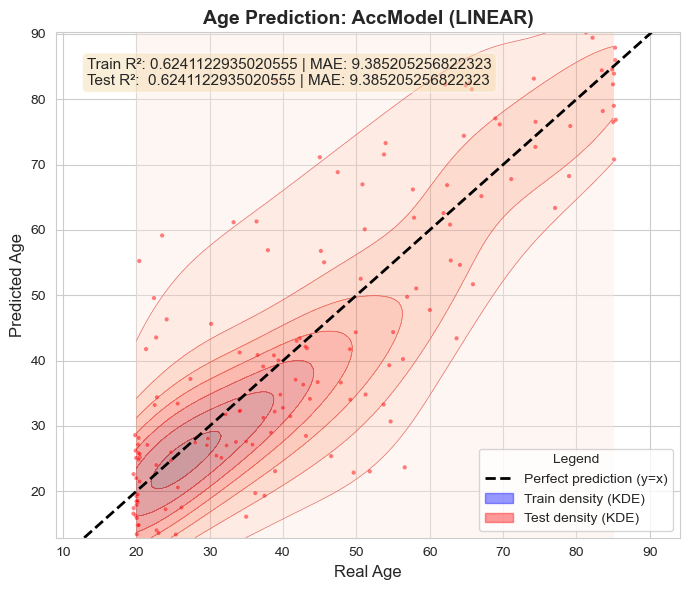

AccModel (RANSAC)
   Train  : R²=0.7114 , Adj‑R²=0.7105 , MAE=8.4048
   Test   : R²=0.6612 , Adj‑R²=0.6589 , MAE=8.8768
 Scatter + KDE saved to: images/scatter_ransac_corr.png


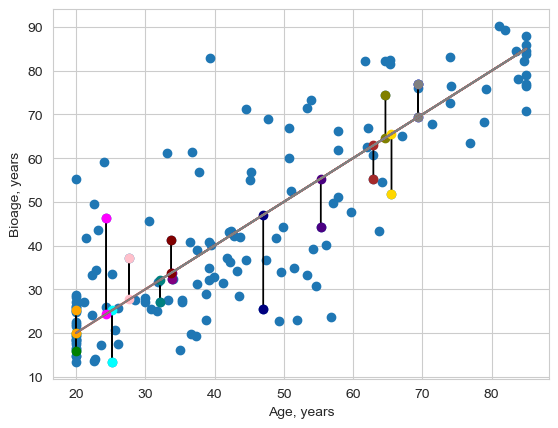

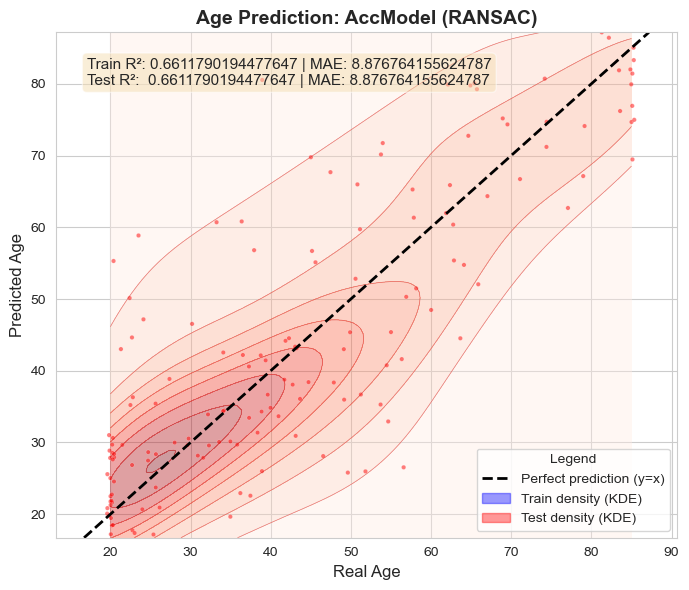

AccModel (THEILSEN)
   Train  : R²=0.7327 , Adj‑R²=0.7320 , MAE=8.1663
   Test   : R²=0.6787 , Adj‑R²=0.6765 , MAE=8.8013
 Scatter + KDE saved to: images/scatter_theilsen_corr.png


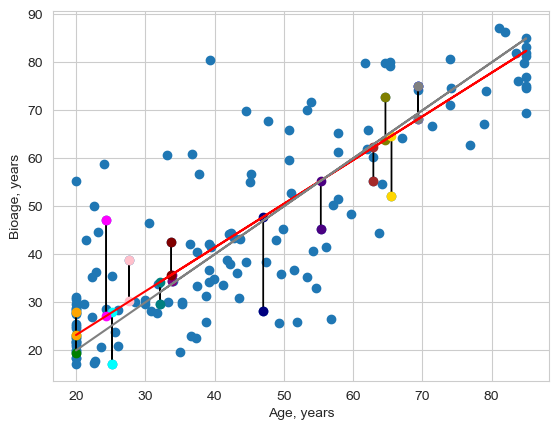

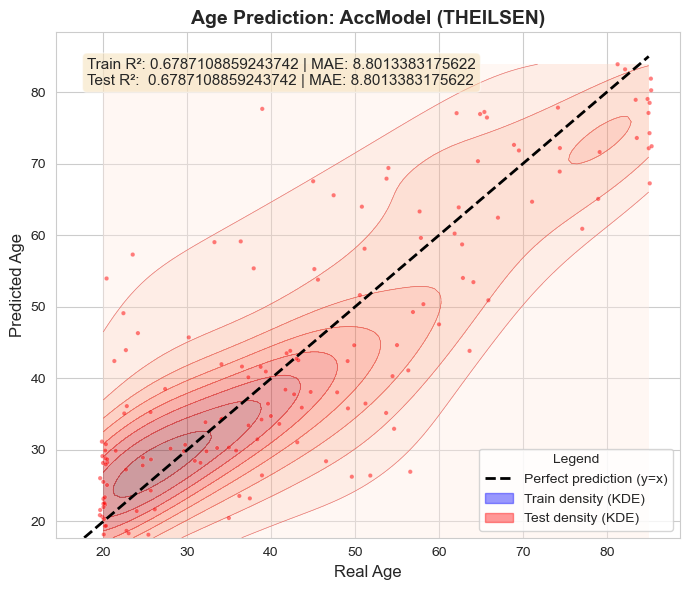


 РЕЗУЛЬТАТЫ (Test Set)
  Method    R²   MAE
  linear 0.624 9.385
  ransac 0.661 8.877
theilsen 0.679 8.801


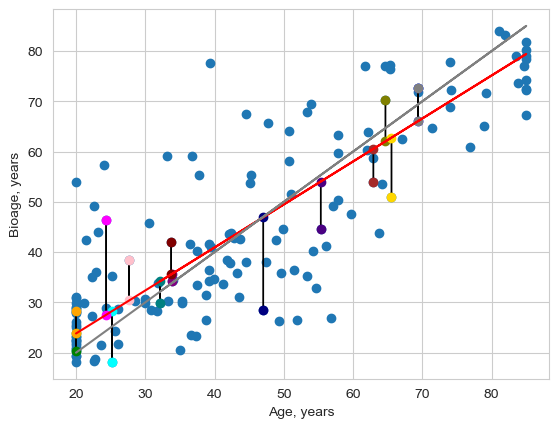

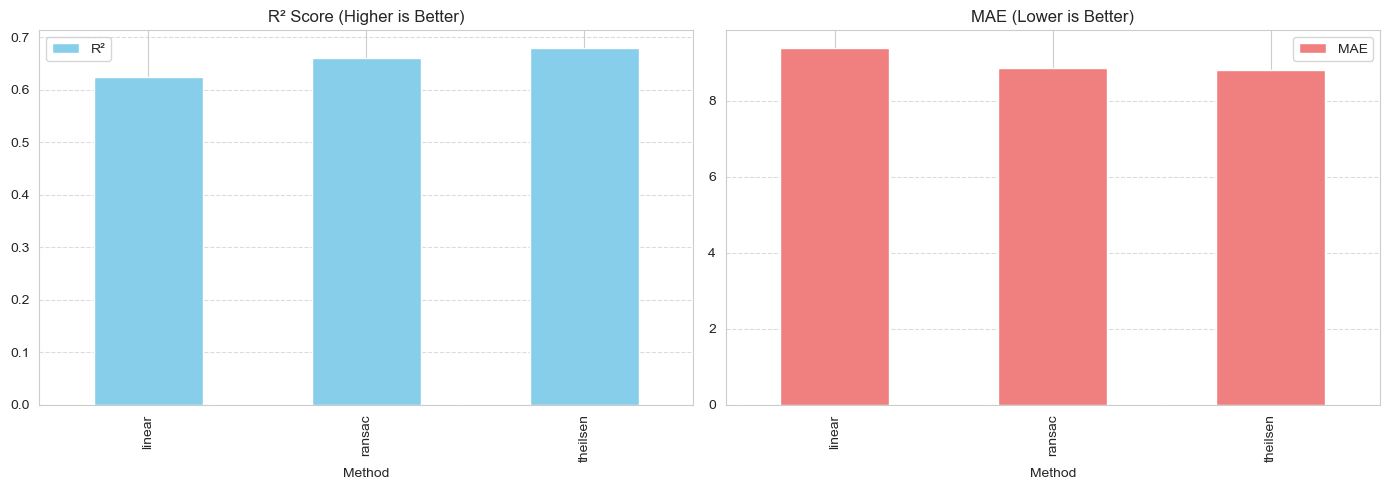

In [81]:
from scipy.stats import gaussian_kde


methods = ['linear', 'ransac', 'theilsen']
results = {}

Params: {'residual_threshold': 1, 'min_samples': 9, 'max_trials': 20}

for method in methods:
    print(f"\n{'='*60}")
    print(f" Training AccModel with {method.upper()}...")
    
    if method == 'ransac':
        linreg_kwargs = {
            'residual_threshold': 1, #2.0,
            'max_trials': 20, #100,
            'min_samples': 9 #max(2, len(y_train) // 4),
            #'random_state': 42,
        }
    elif method == 'theilsen':
        linreg_kwargs = {
            'max_subpopulation': 10,   # 1000
            #'random_state': 42,
        }
    else:          # linear
        linreg_kwargs = {}

    # Создаём AccModel 
    bioage_acc_model = AccModel(
        bioage_model=my_bioage_model,
        bias_correction=True,
        bias_correction_regressor=method,
        bias_correction_regressor_params=linreg_kwargs
    )
    
    #bioage_acc_model.fit(X_train.iloc[:100], y_train[:100])  # обучаем на части данных
    bioage_acc_model.fit(X_train, y_train)

    # Предсказание на тесте
    y_test_pred = bioage_acc_model.predict(X_test)
    
    # Считаем метрики
    r2 = r2_score(y_test, y_test_pred)
    mae = mean_absolute_error(y_test, y_test_pred)
    results[method] = {'r2': r2, 'mae': mae, 'model': bioage_acc_model}
    
    print(f"   Test R²: {r2:.4f}, MAE: {mae:.3f}")

# Визуализация всех трёх моделей

for method in methods:
    model = results[method]['model']
    plot_model_scatter(
        model,
        X_train, y_train,
        X_test, y_test,
        metrics=[results[method]['mae'], results[method]['mae'], results[method]['r2'], results[method]['r2']],
        title=f"AccModel ({method.upper()})",
        fn=f"images/scatter_{method}_corr.png",
        #fn = ''
        plot_train = False
    )
    
    # Покажем калибровку
    model.plot_predict(X_test, y_test)

# Сравнение результатов

print("\n" + "="*60)
print(" РЕЗУЛЬТАТЫ (Test Set)")
print("="*60)
df_results = pd.DataFrame({
    'Method': list(results.keys()),
    'R²': [results[m]['r2'] for m in methods],
    'MAE': [results[m]['mae'] for m in methods]
}).round(3)

print(df_results.to_string(index=False))

# Создаем barplot
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df_results.set_index('Method').plot.bar(y='R²', ax=ax[0], color='skyblue')
ax[0].set_title('R² Score (Higher is Better)')
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

df_results.set_index('Method').plot.bar(y='MAE', ax=ax[1], color='lightcoral')
ax[1].set_title('MAE (Lower is Better)')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()



## Tune parameters

In [21]:
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

methods = ['linear', 'theilsen' , 'ransac']
results = {}

# --- Гиперпараметрические сетки ---
param_grids = {
    'linear': [{}],  # Только один вариант — никаких параметров
    
    'theilsen': [
        {'max_subpopulation': ms}
        for ms in range (2,  5000 ) #max(2, len(y_train)))
    ],
 
    'ransac': [
        # Перебираем все комбинации
        {
            'residual_threshold': th,
            'min_samples': ms,
            'max_trials': mt,
        }
        #for th in np.arange(0.5,20,0.5)[0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]
        for th in range(1,20) 
        for ms in range (2,  max(2, len(y_train)//3))
        for mt in range(10, 300, 10)
    ]

}

for method in methods:
    print(f"\n{'='*60}")
    print(f" Optimizing AccModel with {method.upper()} (grid size: {len(param_grids[method])})...")

    best_mae = float('inf')
    best_params = None
    best_model = None

    # Перебираем все комбинации параметров для данного метода
    for i, params in enumerate(param_grids[method]):
        try:
            bioage_acc_model = AccModel(
                bioage_model=my_bioage_model,
                bias_correction=True,
                bias_correction_regressor=method,
                bias_correction_regressor_params=params
            )
            
            # Обучение на полном обучении
            bioage_acc_model.fit(X_train, y_train)

            # Предсказание на тесте
            y_test_pred = bioage_acc_model.predict(X_test)
            mae = mean_absolute_error(y_test, y_test_pred)
            r2 = r2_score(y_test, y_test_pred)

            if mae < best_mae:
                best_mae = mae
                best_params = params.copy()
                best_model = bioage_acc_model

            # Опционально: показываем прогресс для длинных сеток
            if method == 'ransac' and i % 10 == 0:
                print(f"   [{i+1}/{len(param_grids[method])}] Params: {params} → MAE: {mae:.4f}")

        except Exception as e:
            # Если модель не сходится — пропускаем
            continue

    if best_model is None:
        raise RuntimeError(f"Failed to train any model for method '{method}'")

    results[method] = {
        'r2': r2_score(y_test, best_model.predict(X_test)),
        'mae': best_mae,
        'model': best_model,
        'best_params': best_params
    }

    print(f" BEST for {method.upper()}: MAE={best_mae:.4f}, R²={results[method]['r2']:.4f}")
    print(f"   Params: {best_params}")

# --- Визуализация и сравнение ---
print("\n" + "="*60)
print(" РЕЗУЛЬТАТЫ (Test Set) — ПОСЛЕ ОПТИМИЗАЦИИ")
print("="*60)

df_results = pd.DataFrame({
    'Method': list(results.keys()),
    'R²': [results[m]['r2'] for m in methods],
    'MAE': [results[m]['mae'] for m in methods],
    'Best Params': [str(results[m]['best_params']) for m in methods]
}).round(3)

print(df_results.to_string(index=False))

# Барплоты
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df_results.set_index('Method').plot.bar(y='R²', ax=ax[0], color='skyblue')
ax[0].set_title('R² Score (Higher is Better)')
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

df_results.set_index('Method').plot.bar(y='MAE', ax=ax[1], color='lightcoral')
ax[1].set_title('MAE (Lower is Better)')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Визуализация лучших моделей
for method in methods:
    model = results[method]['model']
    plot_model_scatter(
        model,
        X_train, y_train,
        X_test, y_test,
        metrics=[results[method]['mae'], results[method]['mae'], results[method]['r2'], results[method]['r2']],
        title=f"AccModel ({method.upper()}) — Best Params",
        fn=f"images/scatter_{method}_opt.png",
        plot_train = False
    )
    
    model.plot_predict(X_test, y_test)



 Optimizing AccModel with LINEAR (grid size: 1)...
 BEST for LINEAR: MAE=8.6121, R²=0.7020
   Params: {}

 Optimizing AccModel with THEILSEN (grid size: 4998)...


KeyboardInterrupt: 

In [52]:
len(y_train)

350